In [23]:

from langgraph.graph import StateGraph, START , END
from typing import TypedDict, Annotated,Literal
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langgraph.types import interrupt, Command
from dotenv import load_dotenv
import requests

In [2]:
load_dotenv()

True

In [11]:
llm = ChatOpenAI(model="gpt-4.1-mini")

In [15]:
billing_llm = ChatOpenAI(model='gpt-4o-mini')
technical_llm = ChatOpenAI(model='gpt-4o-mini')
general_llm = ChatOpenAI(model='gpt-4o-mini')

In [16]:
class TicketClassification(BaseModel):
    category:Literal["billing", "technical","general"]
    urgency:Literal["low","medium","high"]
    reasoning: str = Field(description="Reason for classification")

classifier_llm = llm.with_structured_output(TicketClassification)

result = classifier_llm.invoke("I am facing issue in ui of ticket booking , also my family member health is not good , so i hvae to go ")

print(result.category)
print(result.urgency)
print(result.reasoning)

technical
high
The user is experiencing issues with the UI of the ticket booking system, which qualifies as a technical problem. Additionally, the mention of a family member's health concern increases the urgency of resolving this issue quickly.


In [17]:
class TicketState(TypedDict):
    ticket:str
    category:str
    urgency:str
    reasoning:str
    response:str


In [18]:
#classifying the incoming state
def classify_ticket(state:TicketState):
    result = classifier_llm.invoke(f"""
        Classify this customer support ticket.

        Categories:
        - billing: payments, refunds, charges, orders
        - technical: bugs, crashes, login or app issues
        - general: other questions

        Assign urgency as low, medium, or high.

        Ticket: {state['ticket']}
        """)
    return{
        "category":result.category,
        "urgency":result.urgency,
        "reasoning" : result.reasoning
    }

In [19]:
def route_ticket(state:TicketState) ->str:
    category = state['category']

    if category == "billing":
        return "billing_handler"
    elif category == "technical":
        return "technical_handler"
    else:
        return "general_handler"

In [ ]:
def billing_handler(state:TicketState):
    result = billing_llm.invoke(f"""
        You are a customer billing support agent.
        Help with charges, refunds, and payments.
        Do not claim a refund or payment action was completed
        unless it has actually been verified.
        Customer ticket: {state['ticket']}
        Urgency: {state['urgency']}
        """)
    return {"response ":result.content}
    

In [21]:
def technical_handler(state:TicketState):
    result = technical_llm.invoke(f"""
        You are a technical support agent.
        Help customers troubleshoot app errors and technical issues.
        Give clear, practical steps.

        Customer ticket: {state['ticket']}
        Urgency: {state['urgency']}
        """)
    return {"response ":result.content}
    

In [22]:
def general_handler(state: TicketState):
    result = general_llm.invoke(
        f"""
        You are a general customer support agent.
        Answer politely, clearly, and accurately.

        Customer ticket: {state['ticket']}
        Urgency: {state['urgency']}
        """
    )
    return {"response": result.content}

In [24]:
graph=StateGraph(TicketState)

graph.add_node("classify_ticket", classify_ticket)
graph.add_node("billing_handler", billing_handler)
graph.add_node("technical_handler", technical_handler)
graph.add_node("general_handler", general_handler)

graph.add_edge(START, "classify_ticket")

graph.add_conditional_edges("classify_ticket",route_ticket,{"billing_handler": "billing_handler","technical_handler": "technical_handler","general_handler": "general_handler"},)

graph.add_edge("billing_handler", END)
graph.add_edge("technical_handler", END)
graph.add_edge("general_handler", END)

workflow = graph.compile()

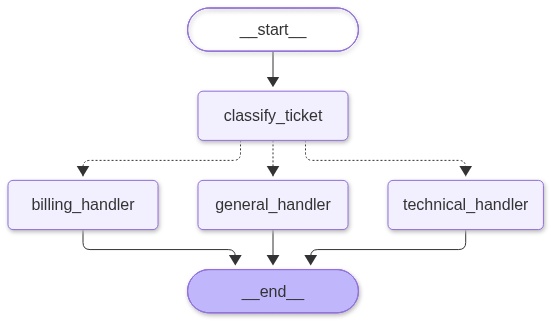

In [25]:
workflow